## Laboratorio 15: Algoritmo KNN

In [1]:
# 1. Importamos librerias
import pandas as pd
import matplotlib.pyplot as plt
# Librerias de Machine Learning
from sklearn.datasets import load_iris#Importamos el datasrt de iris
from sklearn.model_selection import train_test_split# Importamos el metodo de dividir
from sklearn.preprocessing import StandardScaler#Importamos el metodo para escalar
from sklearn.neighbors import KNeighborsClassifier# Importamos el algoritmo
from sklearn.metrics import ( accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)# Importamos las metricas

In [2]:
# 2. Cargamos el dataset
iris = load_iris(as_frame= True)
print (iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [3]:
# Creamos el dataframe
dfIris = iris.frame
dfIris.head(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0


In [4]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [5]:
# Cambiamos la columna Target por Especie
dfIris.rename(columns={"target":"species"}, inplace=True)

In [6]:
dfIris["species"] = dfIris["species"].map(
    {
        0:"Setosa",
        1:"Versicolor",
        2:"Virginica"
    }
)

In [7]:
dfIris.sample(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
131,7.9,3.8,6.4,2.0,Virginica
51,6.4,3.2,4.5,1.5,Versicolor
84,5.4,3.0,4.5,1.5,Versicolor
107,7.3,2.9,6.3,1.8,Virginica
130,7.4,2.8,6.1,1.9,Virginica


In [8]:
# 4. Variables predictoras y variable objetivo
# X -> Variables predictoras
# y -> Variable Objetivo

In [9]:
# Variables predictoras
X = dfIris.drop(columns=["species"])

In [10]:
#Variable Objetivo
y= dfIris["species"]

In [11]:
print ("Variables predictoras")
print(X.columns)
print("--------------------")
print("Variable objetivo")
print(y.name)

Variables predictoras
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='str')
--------------------
Variable objetivo
species


#. DIvisión del conjunto de Datos
# Training Set: Datos para Entrenamiento (70%)
# Test Set: Datos para las pruebas (30%)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, #Variables predictorsas
    y, #Variable Objetivo
    test_size=0.30, #Porcentaje para pruebas
    random_state=42, # Semilla paar garantizar la reproducibilidad
    stratify=y # Para que esten equilibradas las clases
)

In [13]:
print ("X_train: ", X_train.shape)
print ("X_test: ", X_test.shape)
print ("--------------------------")
print ("y_train: ", y_train.shape)
print ("y_test: ", y_test.shape)

X_train:  (105, 4)
X_test:  (45, 4)
--------------------------
y_train:  (105,)
y_test:  (45,)


In [14]:
## 6. Escalado de Variables
scaler = StandardScaler()

In [15]:
# Escalamos las variables numericas, es decir todas las predictoras
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
print("Datos escalados")
print(X_train_scaled)

Datos escalados
[[-0.90045861 -1.22024754 -0.4419858  -0.13661044]
 [ 0.38036614 -1.87955796  0.40282929  0.38029394]
 [-0.90045861  1.63676428 -1.2868009  -1.17041921]
 [ 1.07899781  0.31814344  1.19132338  1.41410271]
 [-0.20182693 -0.56093712  0.17754527  0.12184175]
 [ 0.9625592  -0.12139684  0.79707634  1.41410271]
 [-1.13333583  0.0983733  -1.2868009  -1.4288714 ]
 [-0.90045861  1.63676428 -1.23047989 -1.29964531]
 [-1.7155289  -0.34116698 -1.3431219  -1.29964531]
 [ 1.42831365 -0.12139684  1.19132338  1.15565051]
 [ 0.72968197  0.31814344  0.74075533  1.02642442]
 [-1.13333583 -0.12139684 -1.3431219  -1.29964531]
 [-1.01689722 -0.12139684 -1.23047989 -1.29964531]
 [ 0.14748891 -0.34116698  0.40282929  0.38029394]
 [-0.43470415 -1.44001768  0.00858225 -0.13661044]
 [ 1.54475226  0.31814344  1.24764439  0.76797223]
 [-1.01689722  0.75768372 -1.23047989 -1.04119311]
 [-1.36621306  0.31814344 -1.23047989 -1.29964531]
 [ 0.9625592   0.53791358  1.07868137  1.6725549 ]
 [ 0.0310503   

In [17]:
# 7. Entrenamiento de los datos
modelo = KNeighborsClassifier(
    n_neighbors=3 # Numero de vecinos a checar
)


In [18]:
#Entrenamos el modelo
modelo.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Setosa','Versicolor','Virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [19]:
# Predicicón de pruebas
prediccion = modelo.predict(X_test_scaled)

In [20]:
pd.DataFrame(
    {
        "Especie real: " : y_test.values,
        "Especie predicción: " : prediccion
    }
).head(30)

,Especie real:,Especie predicción:
0,Virginica,Virginica
1,Versicolor,Versicolor
2,Virginica,Versicolor
3,Versicolor,Versicolor
4,Virginica,Virginica
5,Virginica,Virginica
6,Versicolor,Versicolor
7,Versicolor,Versicolor
8,Setosa,Setosa
9,Virginica,Virginica


In [21]:
# Utilizar metricas de evaluación para medir la eficiencia del modelo
# Metricas: f1 Score, accuracy, ROC, Recall

In [22]:
accuracy= accuracy_score(y_test, prediccion)
print (f"Accuracy / Exactitud del modelo KNN: {accuracy : .4f}")

Accuracy / Exactitud del modelo KNN:  0.9111


In [23]:
matrizConfusion = confusion_matrix(y_test, prediccion)
matrizConfusionDF = pd.DataFrame(
    matrizConfusion, 
    index = modelo.classes_,
    columns = modelo.classes_
)
matrizConfusionDF

,Setosa,Versicolor,Virginica
Setosa,15,0,0
Versicolor,0,15,0
Virginica,0,4,11


In [24]:
print(classification_report(y_test, prediccion))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        15
  Versicolor       0.79      1.00      0.88        15
   Virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



In [25]:
# Variables importantes
corr = dfIris.corr(numeric_only= True)

<Axes: >

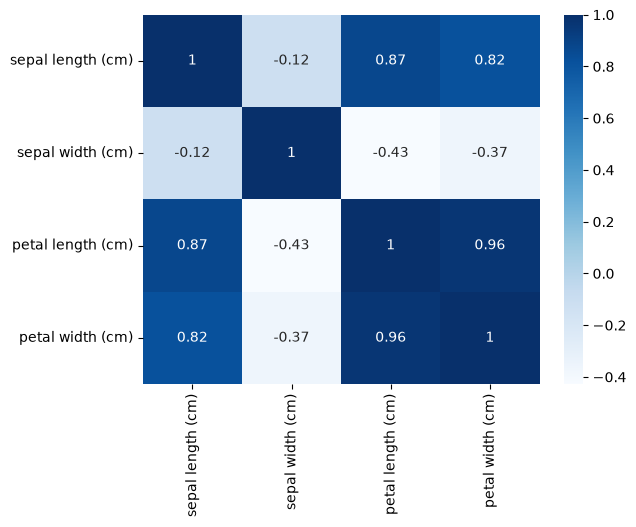

In [26]:
import seaborn as sns
sns.heatmap(corr, annot= True, cmap="Blues")